# LSTM: hiperparámetros, test y semana final

Segunda parte de la LSTM nueva, según `docs/LSTM_DISENO.md`. Parte de los bloques de variables que
eligió `6c_lstm_seleccion.ipynb` y hace cinco cosas:

1. Búsqueda bayesiana de hiperparámetros y del conjunto de variables en 2020-2022.
2. Evaluación de las mejores candidatas con tres semillas, validación del modelo elegido y ensayo
   del procedimiento del test, también en 2020-2022.
3. Test, una sola vez: 2023-2025 y 2026 hasta el 6 de octubre, reentrenando cada mes, en las
   mismas filas de XGBoost y SARIMAX.
4. Semana final, del 9 al 15 de octubre de 2026.
5. Comparación de la LSTM con XGBoost y SARIMAX en el test.

Los pasos 1 y 2 no leen nada de 2023 en adelante. El test y la semana final solo corren con
`CORRER_TEST = True`, y eso se cambia cuando todo lo anterior ya está cerrado.

Se corre en Colab con GPU, con la misma carpeta de salida del notebook 6c (ahí está
`seleccion.json`). Hay que subir `panel_lstm_bloques.csv.gz` y `panel_lstm_bloques_variables.csv`.
Para la comparación final hace falta además `pronosticos_xgboost_sarimax.csv.gz`, que sale de
`6e_pronosticos_para_comparar.py`.
Todo se guarda apenas termina: si la sesión se cae, basta volver a correr y sigue donde iba.

In [21]:
%pip install -q keras-tuner

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
a6d763d0987c4b565d6b09ae3ec4fd37079ab8a93da219847375ac2a2d3a340d  /content/panel_lstm_bloques.csv.gz


In [22]:
import json
import warnings
from math import erf, sqrt
from pathlib import Path

import keras
import keras_tuner as kt
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from keras import layers

# al final de un periodo hay días sin ningún precio objetivo en algún bloque de horizontes; se saltan
warnings.filterwarnings("ignore", message="Mean of empty slice")

# True: corre todo en pocos minutos con una red mínima y sin tocar el test, para revisar que no falle
PRUEBA_RAPIDA = False
# El test se corre una sola vez, con la búsqueda y la validación ya cerradas
CORRER_TEST = True

RUTA = Path("paneles/panel_lstm_bloques.csv.gz")
if not RUTA.exists():
    RUTA = Path("panel_lstm_bloques.csv.gz")
RUTA_VARIABLES = RUTA.with_name("panel_lstm_bloques_variables.csv")

SALIDA = Path("resultados/modelo_lstm_bloques")
# La misma carpeta de Drive del notebook 6c:
from google.colab import drive
drive.mount("/content/drive")
SALIDA = Path("/content/drive/MyDrive/tesis/modelo_lstm_bloques")

HS = list(range(3, 10))
INICIO = "2015-03-01"
FIN_VALIDACION = "2022-12-31"
AÑOS = [2020, 2021, 2022]
SEMILLAS = [0, 1, 2]
VENTANA_MAX = 56
EPOCAS, PACIENCIA = 100, 10
N_BUSQUEDA, N_AL_AZAR = 30, 10

PERIODOS = [("2023_2025", "2023-01-01", "2025-12-31"), ("2026", "2026-01-01", "2026-10-06")]
FILAS_ESPERADAS = {"2023_2025": 183_120, "2026": 45_864}     # las de XGBoost y SARIMAX
ORIGEN_FINAL = "2026-10-06"
BLOQUES_CRITERIO = {"h = 3 a 9": HS, "h = 3": [3], "h = 3 a 7": [3, 4, 5, 6, 7], "h = 8 a 9": [8, 9]}
ARCHIVO_OTROS = "pronosticos_xgboost_sarimax.csv.gz"         # XGBoost y SARIMAX, para la comparación

if PRUEBA_RAPIDA:
    # el código del test se ensaya en un trozo de 2022, no en el test de verdad
    SALIDA = SALIDA / "prueba_rapida"
    SEMILLAS, EPOCAS, N_BUSQUEDA, N_AL_AZAR = [0], 2, 3, 2
    PERIODOS, ORIGEN_FINAL, CORRER_TEST = [("ensayo_2022", "2022-10-01", "2022-12-31")], "2022-12-22", True

TECHO = max([FIN_VALIDACION] + ([p[2] for p in PERIODOS] if CORRER_TEST else []))
(SALIDA / "pronosticos").mkdir(parents=True, exist_ok=True)

sel = json.load(open(SALIDA / "seleccion.json", encoding="utf-8"))
assert sel["prueba_rapida"] == PRUEBA_RAPIDA, "seleccion.json no es de una corrida completa del notebook 6c"

# compiten los conjuntos de las dos selecciones del 6c: la repetida y la primera
primera = sel.get("primera_seleccion", sel)
CONJUNTOS, BLOQUES_DE = {}, {}
for s in (sel, primera):
    nombre = "b12" + "".join(f"_{b}" for b in s["bloques"][2:])
    CONJUNTOS[nombre], BLOQUES_DE[nombre] = s["variables"], s["bloques"]

# configuraciones con las que el 6c ya entrenó esos conjuntos, según el prefijo de sus archivos
YA_ENTRENADAS = {"": primera["configuracion"]}
if sel.get("seleccion_repetida"):
    YA_ENTRENADAS["rep_"] = sel["configuracion"]

print("keras", keras.__version__, "con", keras.backend.backend())
for nombre, v in CONJUNTOS.items():
    print(f"conjunto {nombre}: {', '.join(v) or 'solo precio y calendario'}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
cp: missing destination file operand after '/content/drive/MyDrive/tesis/panel_lstm_bloques_variables.csv'
Try 'cp --help' for more information.
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
keras 3.13.2 con tensorflow
conjunto b12_3: cmg_despacho, disp_decl_hoy_rel, cmg_hoy_vs_precio, frac_termica_prog
conjunto b12_3_4: cmg_despacho, disp_decl_hoy_rel, cmg_hoy_vs_precio, frac_termica_prog, brecha_escasez, presion_hidro_horaria, aportes_media_hist, volumen_util_pct, dias_autonomia


## 1. Datos y modelo

Los mismos del notebook 6c: cada día es un vector con las 24 horas del precio, las variables de los
bloques elegidos y el calendario; el codificador lee los últimos días y el decodificador entrega
los 7 días objetivo, 24 horas cada uno.

In [23]:
info = pd.read_csv(RUTA_VARIABLES).set_index("variable")
panel = pd.read_csv(RUTA, parse_dates=["fecha"]).sort_values(["fecha", "hora"]).reset_index(drop=True)
assert (panel.groupby("fecha").size() == 24).all()

f = pd.DatetimeIndex(panel["fecha"].drop_duplicates())
n_dias = len(f)
dia = panel.iloc[::24].reset_index(drop=True)


def por_dia(col):
    return panel[col].to_numpy(np.float32).reshape(n_dias, 24)


def calendario(dia_semana, festivo):
    return np.column_stack([np.eye(7, dtype=np.float32)[dia_semana], festivo.astype(np.float32)])


LP = por_dia("lp")
Y = np.stack([por_dia(f"y_h{h}") for h in HS], axis=1)                       # [día, 7, 24]
CAL_T = calendario(dia["dia_semana"].to_numpy(), dia["es_festivo"].to_numpy())
CAL_K = np.stack([calendario(dia[f"dia_semana_k{k}"].to_numpy(), dia[f"es_festivo_k{k}"].to_numpy())
                  for k in range(1, 8)], axis=1)                              # [día, 7, 8]

# ingenuo semanal: el precio de esa hora, el mismo día de la semana, en la última semana conocida
Y_SEM = np.full_like(Y, np.nan)
for j, h in enumerate(HS):
    k = 7 * int(np.ceil(h / 7)) - h
    Y_SEM[k:, j] = LP[:n_dias - k] - LP[k:] if k else 0.0

I0 = int(np.searchsorted(f, pd.Timestamp(INICIO)))
PRIMERO = I0 + VENTANA_MAX - 1
con_precio = ~np.isnan(LP).any(axis=1)
completo = ~np.isnan(Y).any(axis=(1, 2))


def origenes(desde, hasta, completos=True):
    # días t desde los que se pronostica; con completos=False basta que h = 3 caiga en el periodo
    assert pd.Timestamp(hasta) <= pd.Timestamp(TECHO), f"no se puede leer más allá de {TECHO}"
    m = (np.arange(n_dias) >= PRIMERO) & (f >= pd.Timestamp(desde)) & con_precio
    if completos:
        m &= completo & (f + pd.Timedelta(days=max(HS)) <= pd.Timestamp(hasta))
    else:
        m &= f + pd.Timedelta(days=min(HS)) <= pd.Timestamp(hasta)
    return np.flatnonzero(m)


def pliegue(año):
    # ajuste, parada temprana (último 10% del entrenamiento) y evaluación (el año)
    corte = pd.Timestamp(f"{año - 1}-12-31")
    tr = origenes(INICIO, corte)
    n_parada = len(tr) // 10
    return tr[:-n_parada - max(HS)], tr[-n_parada:], origenes(corte + pd.Timedelta(days=1), f"{año}-12-31")


def entradas(variables, hasta):
    # vector de cada día, estandarizado con los días de INICIO a `hasta`
    partes = [LP] + [por_dia(v) if info.loc[v, "tipo"] == "horaria" else por_dia(v)[:, :1]
                     for v in variables]
    M = np.hstack(partes)
    ref = M[I0:hasta + 1]
    assert not np.isnan(ref).any()
    M = np.clip((M - ref.mean(axis=0)) / (ref.std(axis=0) + 1e-6), -8, 8)
    return np.hstack([M, CAL_T]).astype(np.float32)


def ventanas(M, idx, ventana):
    return M[idx[:, None] - np.arange(ventana - 1, -1, -1)]


print(f"{n_dias} días, del {f[0].date()} al {f[-1].date()}; se puede leer hasta {TECHO}")

4300 días, del 2015-01-01 al 2026-10-09; se puede leer hasta 2026-10-06


In [24]:
def construir(n_entradas, c):
    historia = keras.Input((c["ventana"], n_entradas))
    semana = keras.Input((len(HS), CAL_K.shape[2]))
    x = layers.Dense(c["densa"], activation="relu")(historia)
    x = layers.Dropout(c["dropout"])(x)
    estados = []
    for _ in range(c["capas"]):
        x, h, s = layers.LSTM(c["unidades"], return_sequences=True, return_state=True)(x)
        estados.append([h, s])
    y = semana
    for estado in estados:
        y = layers.LSTM(c["unidades"], return_sequences=True)(y, initial_state=estado)
    y = layers.Dense(24)(layers.Dropout(c["dropout"])(y))
    modelo = keras.Model([historia, semana], y)
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=c["tasa"]), loss="mse")
    return modelo


def ajustar(c, semilla, tr, parada=None, epocas=EPOCAS):
    # con `parada`, para donde deja de mejorar y devuelve la mejor época; sin ella, corre las épocas dadas
    keras.backend.clear_session()
    keras.utils.set_random_seed(semilla)
    M = entradas(CONJUNTOS[c["conjunto"]], (tr if parada is None else parada)[-1])
    X = lambda idx: [ventanas(M, idx, c["ventana"]), CAL_K[idx]]
    modelo = construir(M.shape[1], c)
    if parada is None:
        modelo.fit(X(tr), Y[tr], epochs=epocas, batch_size=c["lote"], verbose=0)
        return modelo, X, epocas
    parar = keras.callbacks.EarlyStopping(patience=PACIENCIA, restore_best_weights=True)
    hist = modelo.fit(X(tr), Y[tr], validation_data=(X(parada), Y[parada]), epochs=epocas,
                      batch_size=c["lote"], callbacks=[parar], verbose=0)
    return modelo, X, int(np.argmin(hist.history["val_loss"])) + 1


def pronostico(nombre, año, semilla, c):
    # el año, con el modelo entrenado hasta el año anterior y parada temprana; se guarda y no se repite
    ruta = SALIDA / "pronosticos" / f"{nombre}_{año}_s{semilla}.npy"
    if ruta.exists():
        return np.load(ruta)
    aj, par, ev = pliegue(año)
    modelo, X, mejor_epoca = ajustar(c, semilla, aj, par)
    pred = modelo.predict(X(ev), verbose=0)
    np.save(ruta.with_name(ruta.stem + "_epocas.npy"), mejor_epoca)
    np.save(ruta, pred)
    print(f"  {nombre}, {año}, semilla {semilla}: mejor época {mejor_epoca}", flush=True)
    return pred


def con_todo(nombre, hasta, ev, epocas):
    # entrena con todo lo conocido hasta `hasta`, un número fijo de épocas, y pronostica los días `ev`
    ruta = SALIDA / "pronosticos" / f"{nombre}.npy"
    if ruta.exists():
        return np.load(ruta)
    tr = origenes(INICIO, hasta)
    partes = []
    for s in SEMILLAS:
        modelo, X, _ = ajustar(MEJOR, s, tr, epocas=epocas)
        entrada = X(ev)
        assert not np.isnan(entrada[0]).any()
        partes.append(modelo.predict(entrada, verbose=0))
    pred = np.mean(partes, axis=0)
    np.save(ruta, pred)
    print(f"  {nombre}: {len(tr)} días de entrenamiento, {len(ev)} pronosticados", flush=True)
    return pred

## 2. Cómo se mide

El criterio de la tesis, igual que en XGBoost y SARIMAX: un modelo funciona en un bloque de
horizontes si su RMSE en logaritmo es al menos 5% menor que el del mejor de los dos ingenuos y
Diebold-Mariano contra ese ingenuo da p < 0,05, con varianza de Newey-West sobre el error promedio
de cada día.

In [25]:
def validacion(nombre, c, semillas=None):
    # pronósticos de los tres años de validación, con las semillas promediadas
    idx, pred = [], []
    for año in AÑOS:
        idx.append(pliegue(año)[2])
        pred.append(np.mean([pronostico(nombre, año, s, c) for s in (semillas or SEMILLAS)], axis=0))
    return np.concatenate(idx), np.concatenate(pred)


def media_y_ee(d, L):
    n = len(d)
    u = d - d.mean()
    v = np.mean(u * u)
    for l in range(1, min(L, n - 1) + 1):
        v += 2 * (1 - l / (L + 1)) * np.mean(u[l:] * u[:-l])
    return d.mean(), np.sqrt(v / n)


def rmse_semana(idx, pred):
    return float(np.sqrt(np.mean((Y[idx] - pred) ** 2)))


def objetivo(idx, tope):
    # lo que pasó de verdad; los días objetivo que se salen del periodo quedan vacíos
    y = Y[idx].astype(float)
    fuera = (f[idx].to_numpy()[:, None] + np.array(HS, dtype="timedelta64[D]")) > np.datetime64(tope)
    y[fuera] = np.nan
    return y


def entre_modelos(idx, pred_a, pred_b, tope):
    # Diebold-Mariano entre dos modelos en toda la semana; t < 0 si el primero tiene menos error
    y = objetivo(idx, tope)
    d = np.nanmean(((y - pred_a) ** 2 - (y - pred_b) ** 2).reshape(len(idx), -1), axis=1)
    m, ee = media_y_ee(d[~np.isnan(d)], max(HS) - 1 + 7)
    return m / ee, 1 - erf(abs(m / ee) / sqrt(2))


def criterio(idx, pred, tope):
    y = objetivo(idx, tope)
    filas = []
    for nombre, hs in BLOQUES_CRITERIO.items():
        j = [HS.index(h) for h in hs]
        e = y[:, j] - pred[:, j]
        ingenuos = {"del día": y[:, j], "semanal": y[:, j] - Y_SEM[idx][:, j]}
        r_ing = {k: np.sqrt(np.nanmean(v ** 2)) for k, v in ingenuos.items()}
        ref = min(r_ing, key=r_ing.get)
        d = np.nanmean((e ** 2 - ingenuos[ref] ** 2).reshape(len(idx), -1), axis=1)
        m, ee = media_y_ee(d[~np.isnan(d)], max(hs) - 1 + 7)
        r = np.sqrt(np.nanmean(e ** 2))
        mejora, t = 100 * (1 - r / r_ing[ref]), m / ee
        p = 1 - erf(abs(t) / sqrt(2))
        filas.append(dict(bloque=nombre, rmse_log=r, mejor_ingenuo=ref, rmse_ingenuo=r_ing[ref],
                          mejora=mejora, dm_t=t, dm_p=p, funciona=bool(mejora >= 5 and p < 0.05)))
    return pd.DataFrame(filas).set_index("bloque")

## 3. Búsqueda bayesiana de hiperparámetros

30 configuraciones: las 10 primeras al azar y las demás guiadas por las anteriores. Cada una se
entrena con parada temprana y se mide en 2020, 2021 y 2022 con una semilla; el error es el RMSE de
toda la semana con los tres años juntos. Los rangos son los de `docs/LSTM_DISENO.md`, que siguen a
Salazar-Peña et al. (2025).

El conjunto de variables también se busca. Las dos selecciones del notebook 6c no coincidieron:
con la configuración fija entraron los bloques 3 y 4, y con la configuración 2 solo el 3. Por eso
compiten los dos conjuntos, como un hiperparámetro más. Compiten además las combinaciones de
conjunto y configuración que el 6c ya entrenó, sin volver a entrenarlas, y gana la de menor error.

Regla (decisión del autor, tomada el 14 de noviembre de 2026, después de ver las dos selecciones y
antes de correr esta búsqueda y el test).

In [26]:
hp = kt.HyperParameters()
hp.Int("capas", 1, 3)
hp.Choice("unidades", [32, 64, 128, 192, 256, 360])
hp.Choice("densa", [32, 64, 128, 256])
hp.Float("dropout", 0.2, 0.5, step=0.1)
hp.Float("tasa", 1e-5, 1e-2, sampling="log")
hp.Choice("lote", [32, 64])
hp.Choice("ventana", [14, 28, 56])
hp.Choice("conjunto", list(CONJUNTOS))
CLAVES = ["conjunto", "capas", "unidades", "densa", "dropout", "tasa", "lote", "ventana"]


def configuracion(valores):
    c = {k: valores[k] for k in CLAVES}
    c.update({k: int(c[k]) for k in ("capas", "unidades", "densa", "lote", "ventana")})
    c.update(dropout=round(float(c["dropout"]), 1), tasa=float(c["tasa"]))
    if PRUEBA_RAPIDA:
        c.update(capas=min(c["capas"], 2), unidades=16, densa=16)
    return c


class Busqueda(kt.BayesianOptimization):
    def run_trial(self, trial):
        c = configuracion(trial.hyperparameters.values)
        return {"rmse_semana": rmse_semana(*validacion(f"busq_{trial.trial_id}", c, semillas=[0]))}


buscador = Busqueda(objective=kt.Objective("rmse_semana", "min"), max_trials=N_BUSQUEDA,
                    num_initial_points=N_AL_AZAR, seed=0, hyperparameters=hp, tune_new_entries=False,
                    directory=str(SALIDA), project_name="busqueda_conjuntos")
buscador.search()

pruebas = [dict(configuracion=t.trial_id, **configuracion(t.hyperparameters.values), rmse_semana=t.score)
           for t in buscador.oracle.trials.values() if t.score is not None]
for prefijo, c in YA_ENTRENADAS.items():
    for conjunto in CONJUNTOS:
        if all((SALIDA / "pronosticos" / f"{prefijo}{conjunto}_{año}_s0.npy").exists() for año in AÑOS):
            pruebas.append(dict(configuracion="6c, selección " + ("repetida" if prefijo else "primera"),
                                **dict(c, conjunto=conjunto),
                                rmse_semana=rmse_semana(*validacion(prefijo + conjunto, c, semillas=[0]))))
pruebas = pd.DataFrame(pruebas).sort_values("rmse_semana").reset_index(drop=True)
pruebas.to_csv(SALIDA / "busqueda.csv", index=False)

print("Mejor con una semilla:", pruebas.loc[0, "configuracion"], configuracion(pruebas.loc[0, CLAVES].to_dict()))
print("Mejor de cada conjunto:")
print(pruebas.groupby("conjunto")["rmse_semana"].min().round(5).to_string())
pruebas.round(5)

Reloading Tuner from /content/drive/MyDrive/tesis/modelo_lstm_bloques/busqueda_conjuntos/tuner0.json
Mejor con una semilla: 01 {'conjunto': 'b12_3_4', 'capas': 1, 'unidades': 192, 'densa': 128, 'dropout': 0.3, 'tasa': 0.002510676487272628, 'lote': 64, 'ventana': 56}
Mejor de cada conjunto:
conjunto
b12_3      0.25058
b12_3_4    0.24388


,configuracion,conjunto,capas,unidades,densa,dropout,tasa,lote,ventana,rmse_semana
0,01,b12_3_4,1,192,128,0.3,0.00251,64,56,0.24388
1,"6c, selección primera",b12_3_4,1,128,64,0.2,0.00100,32,28,0.24601
2,23,b12_3,2,192,128,0.2,0.00061,64,14,0.25058
3,00,b12_3,2,256,128,0.2,0.00067,64,14,0.25089
4,25,b12_3_4,2,360,32,0.3,0.00056,64,14,0.25127
5,20,b12_3,2,192,128,0.3,0.00343,64,14,0.25145
6,"6c, selección repetida",b12_3_4,2,192,128,0.5,0.00280,64,14,0.25155
7,17,b12_3_4,1,32,128,0.4,0.00040,64,14,0.25232
8,"6c, selección primera",b12_3,1,128,64,0.2,0.00100,32,28,0.25308
9,26,b12_3,1,32,64,0.4,0.00031,64,14,0.25509


## 4. Evaluación con tres semillas y validación del modelo elegido

La búsqueda mide cada configuración con una semilla, y una sola corrida de la red es ruidosa. En la
primera corrida de este notebook, la misma configuración con la misma semilla dio 15,5% de mejora
en la búsqueda y 11,7% al repetirla: la GPU no es del todo determinista y eso cambia la época en
que para el entrenamiento. Diferencias de menos de un punto entre configuraciones no se pueden
distinguir así. Por eso la búsqueda solo propone candidatas y la decisión se toma con el promedio
de tres semillas, como en la selección de bloques.

Regla (decisión del autor, tomada el 14 de noviembre de 2026, después de ver la primera corrida de
la búsqueda y antes de correr esta evaluación y el test): se evalúan con tres semillas las cinco
mejores configuraciones de la búsqueda, y compiten también las combinaciones del 6c que ya tienen
tres semillas. Gana la de menor RMSE de la semana con las tres semillas promediadas.

La ganadora se vuelve a entrenar con tres semillas nuevas corridas. Elegir la mejor de nueve
candidatas favorece a la que tuvo suerte, así que su error en la evaluación es optimista; la
corrida nueva da una cifra más honesta, y es la que se compara con el ensayo. De ella sale también
el número de épocas para el test: la mediana de la mejor época.

Después, un ensayo del procedimiento del test. La parada temprana aparta el último 10% del
entrenamiento, así que el modelo no aprende de los meses más recientes. En el test eso no conviene:
cada modelo se entrena con todo lo conocido hasta su corte, durante ese número fijo de épocas y sin
parada temprana (decisión del autor). Aquí se ensaya ese mismo procedimiento en 2020-2022,
entrenando una vez por año, para ver qué error da antes de abrir el test. La regla quedó fijada
antes de correrlo: si el ensayo sale peor que la parada temprana con Diebold-Mariano p < 0,05 en el
error de la semana, el test no se abre y se revisa el procedimiento.

Estos números son optimistas: 2020-2022 se usó para elegir los bloques y los hiperparámetros.

In [27]:
N_CANDIDATAS = 2 if PRUEBA_RAPIDA else 5
candidatas = []
de_busqueda = pruebas[~pruebas["configuracion"].astype(str).str.startswith("6c")].head(N_CANDIDATAS)
for _, fila in de_busqueda.iterrows():
    candidatas.append((f"busq_{fila['configuracion']}", f"búsqueda {fila['configuracion']}",
                       configuracion(fila[CLAVES].to_dict())))
for prefijo, c in YA_ENTRENADAS.items():
    for conjunto in CONJUNTOS:
        nombre = prefijo + conjunto
        if all((SALIDA / "pronosticos" / f"{nombre}_{año}_s{s}.npy").exists() for año in AÑOS for s in SEMILLAS):
            candidatas.append((nombre, "6c, selección " + ("repetida" if prefijo else "primera"),
                               dict(c, conjunto=conjunto)))

filas, PRED_VAL = [], {}
for nombre, origen, c in candidatas:
    idx_val, PRED_VAL[nombre] = validacion(nombre, c)
    filas.append(dict(candidata=nombre, origen=origen, **c, rmse_semana=rmse_semana(idx_val, PRED_VAL[nombre]),
                      mejora_semana=criterio(idx_val, PRED_VAL[nombre], FIN_VALIDACION).loc["h = 3 a 9", "mejora"]))
tres = pd.DataFrame(filas).sort_values("rmse_semana").reset_index(drop=True)
tres.to_csv(SALIDA / "evaluacion_tres_semillas.csv", index=False)

GANADORA = tres.loc[0, "candidata"]
MEJOR = next(c for n, _, c in candidatas if n == GANADORA)
VARIABLES = CONJUNTOS[MEJOR["conjunto"]]
pred_val = PRED_VAL[GANADORA]
t, p = entre_modelos(idx_val, pred_val, PRED_VAL[tres.loc[1, "candidata"]], FIN_VALIDACION)
print(f"Gana {GANADORA} ({tres.loc[0, 'origen']}):", MEJOR)
print(f"Contra la segunda, {tres.loc[1, 'candidata']}: t = {t:.2f}, p = {p:.3f}")
tres.round(4)

Gana b12_3_4 (6c, selección primera): {'capas': 1, 'unidades': 128, 'densa': 64, 'dropout': 0.2, 'tasa': 0.001, 'lote': 32, 'ventana': 28, 'conjunto': 'b12_3_4'}
Contra la segunda, busq_01: t = -1.82, p = 0.068


,candidata,origen,conjunto,capas,unidades,densa,dropout,tasa,lote,ventana,rmse_semana,mejora_semana
0,b12_3_4,"6c, selección primera",b12_3_4,1,128,64,0.2,0.0010,32,28,0.2405,16.7080
1,busq_01,búsqueda 01,b12_3_4,1,192,128,0.3,0.0025,64,56,0.2446,15.2997
2,rep_b12_3_4,"6c, selección repetida",b12_3_4,2,192,128,0.5,0.0028,64,14,0.2476,14.2465
3,busq_25,búsqueda 25,b12_3_4,2,360,32,0.3,0.0006,64,14,0.2489,13.7965
4,busq_00,búsqueda 00,b12_3,2,256,128,0.2,0.0007,64,14,0.2497,13.5381
5,rep_b12_3,"6c, selección repetida",b12_3,2,192,128,0.5,0.0028,64,14,0.2512,13.0194
6,busq_20,búsqueda 20,b12_3,2,192,128,0.3,0.0034,64,14,0.2524,12.5950
7,b12_3,"6c, selección primera",b12_3,1,128,64,0.2,0.0010,32,28,0.2524,12.5895
8,busq_23,búsqueda 23,b12_3,2,192,128,0.2,0.0006,64,14,0.2530,12.3889


In [28]:
# la ganadora, entrenada otra vez con parada temprana: su error y sus mejores épocas
_, pred_val = validacion(f"val_{GANADORA}", MEJOR)
epocas = [int(np.load(SALIDA / "pronosticos" / f"val_{GANADORA}_{año}_s{s}_epocas.npy"))
          for año in AÑOS for s in SEMILLAS]
print(f"{GANADORA}: {tres.loc[0, 'mejora_semana']:.1f}% de mejora en la evaluación y "
      f"{criterio(idx_val, pred_val, FIN_VALIDACION).loc['h = 3 a 9', 'mejora']:.1f}% en la corrida nueva")
EPOCAS_TEST = int(np.median(epocas))
print("Mejores épocas:", epocas, "| épocas para el test:", EPOCAS_TEST)

pred_ensayo = np.concatenate([con_todo(f"ensayo_{GANADORA}_{año}", f"{año - 1}-12-31", pliegue(año)[2],
                                       EPOCAS_TEST) for año in AÑOS])

val = pd.concat({"parada temprana": criterio(idx_val, pred_val, FIN_VALIDACION),
                 "como en el test": criterio(idx_val, pred_ensayo, FIN_VALIDACION)}, names=["procedimiento"])
val.to_csv(SALIDA / "validacion_criterio.csv")

t_ensayo, p_ensayo = entre_modelos(idx_val, pred_ensayo, pred_val, FIN_VALIDACION)
ENSAYO_PEOR = bool(t_ensayo > 0 and p_ensayo < 0.05)
print(f"Ensayo contra parada temprana: t = {t_ensayo:.2f}, p = {p_ensayo:.3f}. "
      + ("El ensayo sale peor: el test no se abre." if ENSAYO_PEOR else "Se usa el procedimiento del test."))

configuracion_final = dict(candidata=GANADORA, bloques=BLOQUES_DE[MEJOR["conjunto"]], variables=VARIABLES,
                           **MEJOR, epocas=EPOCAS_TEST,
                           semillas=SEMILLAS, perdida="mse", reentrenar="mensual",
                           ensayo_dm_t=float(t_ensayo), ensayo_dm_p=float(p_ensayo))
json.dump(configuracion_final, open(SALIDA / "configuracion_final.json", "w", encoding="utf-8"),
          indent=2, ensure_ascii=False)
val.round(4)

b12_3_4: 16.7% de mejora en la evaluación y 16.6% en la corrida nueva
Mejores épocas: [3, 4, 2, 4, 4, 2, 7, 13, 3] | épocas para el test: 4
Ensayo contra parada temprana: t = 1.73, p = 0.083. Se usa el procedimiento del test.


rmse_log mejor_ingenuo  rmse_ingenuo   mejora  \
procedimiento   bloque                                                     
parada temprana h = 3 a 9    0.2408       del día        0.2888  16.6111   
                h = 3        0.1799       del día        0.2351  23.4851   
                h = 3 a 7    0.2216       del día        0.2709  18.1790   
                h = 8 a 9    0.2831       del día        0.3293  14.0230   
como en el test h = 3 a 9    0.2466       del día        0.2888  14.5962   
                h = 3        0.1801       del día        0.2351  23.4130   
                h = 3 a 7    0.2264       del día        0.2709  16.4205   
                h = 8 a 9    0.2911       del día        0.3293  11.5949   

                             dm_t    dm_p  funciona  
procedimiento   bloque                               
parada temprana h = 3 a 9 -5.1798  0.0000      True  
                h = 3     -6.9571  0.0000      True  
                h = 3 a 7 -5.7807  0.0000      True  
                h = 8 a 9 -4.2459  0.0000      True  
como en el test h = 3 a 9 -4.0949  0.0000      True  
                h = 3     -6.7585  0.0000      True  
                h = 3 a 7 -4.7766  0.0000      True  
                h = 8 a 9 -3.0611  0.0022      True

## 5. Test

Una sola vez, con `CORRER_TEST = True` y la configuración ya guardada en
`configuracion_final.json`. El modelo se reentrena el primer día de cada mes con todos los días
cuyos precios objetivo ya se conocen, y pronostica desde cada día del mes. Las filas son las mismas
de XGBoost y SARIMAX. Si los pronósticos del test ya existen, se leen y no se vuelven a calcular.

In [29]:
def walk_forward(nombre, desde, hasta):
    cortes = pd.date_range(desde, hasta, freq="MS")
    idx, pred = [], []
    for k, corte in enumerate(cortes):
        fin = cortes[k + 1] - pd.Timedelta(days=1) if k + 1 < len(cortes) else pd.Timestamp(hasta)
        ev = origenes(corte, hasta, completos=False)
        ev = ev[f[ev] <= fin]
        idx.append(ev)
        pred.append(con_todo(f"{nombre}_{corte:%Y_%m}", corte - pd.Timedelta(days=1), ev, EPOCAS_TEST))
    return np.concatenate(idx), np.concatenate(pred)


def a_filas(idx, pred, tope):
    n = len(idx)
    d = pd.DataFrame({"fecha": np.repeat(f[idx], len(HS) * 24),
                      "hora": np.tile(np.arange(1, 25), n * len(HS)),
                      "h": np.tile(np.repeat(HS, 24), n),
                      "y_hat": pred.reshape(-1)})
    return d[d["fecha"] + pd.to_timedelta(d["h"], unit="D") <= pd.Timestamp(tope)]


if CORRER_TEST:
    assert PRUEBA_RAPIDA or not ENSAYO_PEOR, "el ensayo salió peor que la parada temprana: revisar antes del test"
    tablas = []
    for nombre, desde, hasta in PERIODOS:
        ruta = SALIDA / f"prueba_{nombre}.csv.gz"
        idx, pred = walk_forward(f"prueba_{GANADORA}_{nombre}", desde, hasta)
        filas = a_filas(idx, pred, hasta)
        assert len(filas) == FILAS_ESPERADAS.get(nombre, len(filas)), "no son las filas de XGBoost y SARIMAX"
        if not ruta.exists():
            filas.to_csv(ruta, index=False)
        tablas.append(criterio(idx, pred, hasta).assign(periodo=nombre))
    veredicto = pd.concat(tablas)
    veredicto.to_csv(SALIDA / "prueba_criterio.csv")
    display(veredicto.round(4))
else:
    print("El test no se corrió: CORRER_TEST = False")

  prueba_b12_3_4_2023_2025_2023_01: 2799 días de entrenamiento, 31 pronosticados


  prueba_b12_3_4_2023_2025_2023_02: 2830 días de entrenamiento, 28 pronosticados
  prueba_b12_3_4_2023_2025_2023_03: 2858 días de entrenamiento, 31 pronosticados
  prueba_b12_3_4_2023_2025_2023_04: 2889 días de entrenamiento, 30 pronosticados
  prueba_b12_3_4_2023_2025_2023_05: 2919 días de entrenamiento, 31 pronosticados
  prueba_b12_3_4_2023_2025_2023_06: 2950 días de entrenamiento, 30 pronosticados
  prueba_b12_3_4_2023_2025_2023_07: 2980 días de entrenamiento, 31 pronosticados
  prueba_b12_3_4_2023_2025_2023_08: 3011 días de entrenamiento, 31 pronosticados
  prueba_b12_3_4_2023_2025_2023_09: 3042 días de entrenamiento, 30 pronosticados
  prueba_b12_3_4_2023_2025_2023_10: 3072 días de entrenamiento, 31 pronosticados
  prueba_b12_3_4_2023_2025_2023_11: 3103 días de entrenamiento, 30 pronosticados
  prueba_b12_3_4_2023_2025_2023_12: 3133 días de entrenamiento, 31 pronosticados
  prueba_b12_3_4_2023_2025_2024_01: 3164 días de entrenamiento, 31 pronosticados
  prueba_b12_3_4_2023_2025_2

,rmse_log,mejor_ingenuo,rmse_ingenuo,mejora,dm_t,dm_p,funciona,periodo
bloque,,,,,,,,
h = 3 a 9,0.4271,del día,0.5018,14.8798,-4.6172,0.0000,True,2023_2025
h = 3,0.3105,del día,0.4115,24.5470,-8.7827,0.0000,True,2023_2025
h = 3 a 7,0.3895,del día,0.4720,17.4784,-5.6043,0.0000,True,2023_2025
h = 8 a 9,0.5095,del día,0.5698,10.5845,-3.0263,0.0025,True,2023_2025
h = 3 a 9,0.3495,del día,0.4353,19.7114,-3.6589,0.0003,True,2026
h = 3,0.2540,del día,0.3524,27.9250,-4.5615,0.0000,True,2026
h = 3 a 7,0.3203,del día,0.4087,21.6202,-3.9301,0.0001,True,2026
h = 8 a 9,0.4143,del día,0.4964,16.5370,-3.0833,0.0020,True,2026


## 6. Semana final

Pronóstico del 9 al 15 de octubre de 2026 con el último precio conocido, el del 6 de octubre.
Se entrena con todos los días cuyos precios objetivo ya se conocen. Es una demostración: una sola
semana no mide el modelo. Si está `precio_real_final.csv`, el que se bajó para XGBoost, se compara
contra el precio real.

In [30]:
if CORRER_TEST:
    i = int(np.flatnonzero(f == pd.Timestamp(ORIGEN_FINAL))[0])
    pred = con_todo(f"semana_final_{GANADORA}_{ORIGEN_FINAL}", ORIGEN_FINAL, np.array([i]), EPOCAS_TEST)[0]
    final = pd.DataFrame({"origen": ORIGEN_FINAL,
                          "fecha_objetivo": np.repeat(f[i] + pd.to_timedelta(HS, unit="D"), 24),
                          "h": np.repeat(HS, 24), "hora": np.tile(np.arange(1, 25), len(HS)),
                          "precio_t": np.tile(np.exp(LP[i]), len(HS)), "y_hat": pred.reshape(-1)})
    final["precio_pron"] = final["precio_t"] * np.exp(final["y_hat"])
    final.to_csv(SALIDA / "pronostico_final.csv", index=False)

    rutas = [Path("resultados/modelo_xgboost/precio_real_final.csv"), Path("precio_real_final.csv")]
    real = next((r for r in rutas if r.exists()), None)
    if real is not None and not PRUEBA_RAPIDA:
        d = final.merge(pd.read_csv(real, parse_dates=["fecha_objetivo"]), on=["fecha_objetivo", "hora"])
        assert len(d) == 168
        e = np.log(d["precio_real"]) - np.log(d["precio_pron"])
        e_dia = np.log(d["precio_real"]) - np.log(d["precio_t"])
        resumen = pd.DataFrame({"LSTM": [np.sqrt(np.mean(e ** 2)), 100 * np.mean(np.abs(d["precio_pron"] / d["precio_real"] - 1))],
                                "ingenuo del día": [np.sqrt(np.mean(e_dia ** 2)), 100 * np.mean(np.abs(d["precio_t"] / d["precio_real"] - 1))]},
                               index=["RMSE log", "MAPE (%)"])
        resumen.to_csv(SALIDA / "semana_final_resumen.csv")
        display(resumen.round(3))
    else:
        display(final.head())
else:
    print("La semana final no se corrió: CORRER_TEST = False")

  semana_final_b12_3_4_2026-10-06: 4174 días de entrenamiento, 1 pronosticados


,origen,fecha_objetivo,h,hora,precio_t,y_hat,precio_pron
0,2026-10-06,2026-10-09,3,1,419.846771,0.208958,517.416443
1,2026-10-06,2026-10-09,3,2,419.846771,0.206846,516.324768
2,2026-10-06,2026-10-09,3,3,419.846771,0.167520,496.413666
3,2026-10-06,2026-10-09,3,4,447.112335,0.223544,559.114441
4,2026-10-06,2026-10-09,3,5,610.421814,0.174886,727.079895


## 7. Comparación de los tres modelos

La LSTM frente a XGBoost y SARIMAX en el test, con las mismas filas: los mismos días, horas y
horizontes. Los pronósticos de XGBoost y SARIMAX se leen de `pronosticos_xgboost_sarimax.csv.gz`,
ya calculados en `4_modelo_xgboost.ipynb` y `5_modelo_sarimax.ipynb`; aquí no se vuelve a entrenar
ninguno. Los tres se miden con las mismas funciones de la sección 2.

Solo corre con el test hecho (`CORRER_TEST = True`) y con ese archivo en la carpeta de trabajo, en
`resultados/comparacion/` o en la carpeta de salida.

In [31]:
MODELOS = ["LSTM", "XGBoost", "SARIMAX"]
COLOR = {"LSTM": "#2a78d6", "XGBoost": "#eb6834", "SARIMAX": "#1baf7a"}
PARES = [("LSTM", "XGBoost"), ("LSTM", "SARIMAX"), ("XGBoost", "SARIMAX")]


def a_matriz(tabla, columna, idx):
    # de filas (fecha, hora, h) a [día, horizonte, hora], en el orden de idx
    lugar = pd.Series(np.arange(len(idx)), index=f[idx])
    m = np.full((len(idx), len(HS), 24), np.nan)
    m[lugar.loc[tabla["fecha"]].to_numpy(), tabla["h"].to_numpy() - HS[0],
      tabla["hora"].to_numpy() - 1] = tabla[columna].to_numpy()
    return m


rutas = [Path("resultados/comparacion"), Path("."), SALIDA, SALIDA.parent]
otros = next((r / ARCHIVO_OTROS for r in rutas if (r / ARCHIVO_OTROS).exists()), None)
COMPARAR = CORRER_TEST and not PRUEBA_RAPIDA and otros is not None

if COMPARAR:
    tabla_otros = pd.read_csv(otros, parse_dates=["fecha"], dtype={"periodo": str})
    IDX, PRED, TOPE = {}, {}, {}
    for nombre, desde, hasta in PERIODOS:
        idx = origenes(desde, hasta, completos=False)
        o = tabla_otros[tabla_otros["periodo"] == nombre]
        lstm = pd.read_csv(SALIDA / f"prueba_{nombre}.csv.gz", parse_dates=["fecha"])
        assert len(lstm) == len(o) == FILAS_ESPERADAS[nombre]
        IDX[nombre], TOPE[nombre] = idx, hasta
        PRED[nombre] = {"LSTM": a_matriz(lstm, "y_hat", idx),
                        "XGBoost": a_matriz(o, "y_hat_xgboost", idx),
                        "SARIMAX": a_matriz(o, "y_hat_sarimax", idx)}
        vacios = [np.isnan(p) for p in PRED[nombre].values()]
        assert all((v == vacios[0]).all() for v in vacios), "los tres modelos no tienen las mismas filas"
        print(f"{nombre}: {len(lstm):,} pronósticos por modelo, en las mismas filas")
else:
    print("No se compara:", "es la prueba rápida" if PRUEBA_RAPIDA else "falta correr el test"
          if not CORRER_TEST else f"falta subir {ARCHIVO_OTROS}")

2023_2025: 183,120 pronósticos por modelo, en las mismas filas
2026: 45,864 pronósticos por modelo, en las mismas filas


### 7.1 Criterio de la tesis

Cada modelo contra el mejor ingenuo, en la semana completa y en los tres bloques de horizontes.

In [32]:
if COMPARAR:
    crit = pd.concat({(p, m): criterio(IDX[p], PRED[p][m], TOPE[p]) for p in PRED for m in MODELOS},
                     names=["periodo", "modelo"])
    crit.to_csv(SALIDA / "comparacion_criterio.csv")
    semana = crit.xs("h = 3 a 9", level="bloque")[["rmse_log", "rmse_ingenuo", "mejora", "dm_p", "funciona"]]
    display(semana.round(4))
    display(crit["mejora"].unstack("bloque")[list(BLOQUES_CRITERIO)].round(1))

rmse_log  rmse_ingenuo   mejora    dm_p  funciona
periodo   modelo                                                    
2023_2025 LSTM       0.4271        0.5018  14.8798  0.0000      True
          XGBoost    0.4434        0.5018  11.6381  0.0000      True
          SARIMAX    0.4697        0.5018   6.4087  0.0000      True
2026      LSTM       0.3495        0.4353  19.7114  0.0003      True
          XGBoost    0.3920        0.4353   9.9616  0.0010      True
          SARIMAX    0.4110        0.4353   5.5901  0.0004      True

bloque             h = 3 a 9  h = 3  h = 3 a 7  h = 8 a 9
periodo   modelo                                         
2023_2025 LSTM          14.9   24.5       17.5       10.6
          SARIMAX        6.4    7.7        6.4        6.4
          XGBoost       11.6   17.9       12.5       10.1
2026      LSTM          19.7   27.9       21.6       16.5
          SARIMAX        5.6    6.5        5.6        5.6
          XGBoost       10.0   19.5       11.6        7.2

La primera tabla es la semana completa: el RMSE en logaritmo, el del mejor ingenuo, la mejora en
porcentaje y el valor p de Diebold-Mariano contra ese ingenuo. La segunda es la mejora, en
porcentaje, en cada bloque de horizontes.

### 7.2 Por horizonte

Mejora del RMSE frente al ingenuo del día en cada horizonte. El ingenuo del día es el mejor de los
dos en todos los horizontes del test.

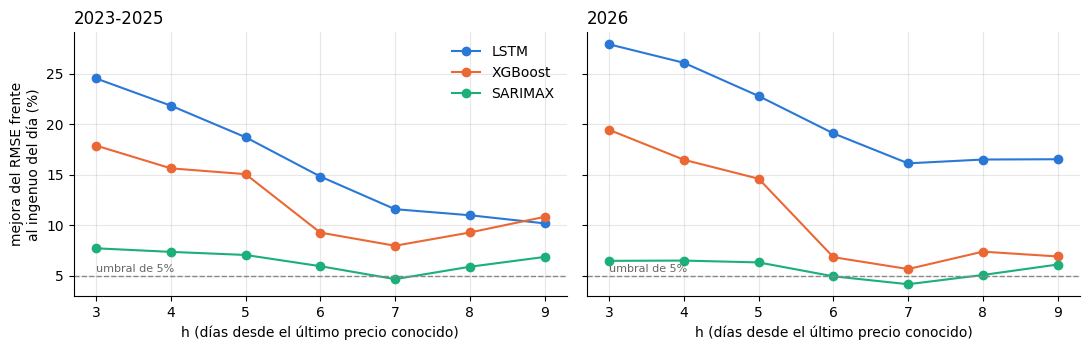

2023_2025                  2026                
       LSTM XGBoost SARIMAX  LSTM XGBoost SARIMAX
h                                                
3      24.5    17.9     7.7  27.9    19.5     6.5
4      21.9    15.7     7.4  26.1    16.5     6.5
5      18.7    15.1     7.1  22.8    14.6     6.3
6      14.8     9.3     6.0  19.1     6.9     5.0
7      11.6     8.0     4.7  16.1     5.7     4.2
8      11.0     9.3     5.9  16.5     7.4     5.1
9      10.2    10.8     6.9  16.6     6.9     6.1

In [33]:
def mejora_por_h(p, m):
    y = objetivo(IDX[p], TOPE[p])
    r = lambda e: np.sqrt(np.nanmean(e ** 2, axis=(0, 2)))
    return 100 * (1 - r(y - PRED[p][m]) / r(y))


if COMPARAR:
    por_h = pd.DataFrame({(p, m): mejora_por_h(p, m) for p in PRED for m in MODELOS},
                         index=pd.Index(HS, name="h"))
    fig, ejes = plt.subplots(1, len(PRED), figsize=(11, 3.6), sharey=True)
    for ax, p in zip(ejes, PRED):
        for m in MODELOS:
            ax.plot(HS, por_h[(p, m)], marker="o", color=COLOR[m], label=m)
        ax.axhline(5, color="#888888", ls="--", lw=1)
        ax.text(HS[0], 5.4, "umbral de 5%", color="#666666", fontsize=8)
        ax.set_title(p.replace("_", "-"), loc="left")
        ax.set_xlabel("h (días desde el último precio conocido)")
        ax.grid(alpha=0.3)
        ax.spines[["top", "right"]].set_visible(False)
    ejes[0].set_ylabel("mejora del RMSE frente\nal ingenuo del día (%)")
    ejes[0].legend(frameon=False)
    plt.tight_layout()
    plt.savefig(SALIDA / "comparacion_por_horizonte.png", dpi=150)
    plt.show()
    display(por_h.round(1))

### 7.3 Comparación directa

Diebold-Mariano entre cada par de modelos, con el error de toda la semana. Tener menor RMSE no
basta para decir que un modelo es mejor: la diferencia tiene que ser significativa (p < 0,05). El
año es el del día en que se hace el pronóstico.

In [34]:
if COMPARAR:
    filas = []
    casos = [(p, p, np.ones(len(IDX[p]), bool)) for p in PRED]
    casos += [(str(a), "2023_2025", f[IDX["2023_2025"]].year == a) for a in (2023, 2024, 2025)]
    for etiqueta, p, m in casos:
        y = objetivo(IDX[p][m], TOPE[p])
        rmse = {k: np.sqrt(np.nanmean((y - PRED[p][k][m]) ** 2)) for k in MODELOS}
        for a, b in PARES:
            t, pv = entre_modelos(IDX[p][m], PRED[p][a][m], PRED[p][b][m], TOPE[p])
            filas.append({"periodo": etiqueta, "comparación": f"{a} y {b}", "RMSE del primero": rmse[a],
                          "RMSE del segundo": rmse[b], "dm_t": t, "dm_p": pv,
                          "menor error": a if t < 0 else b, "significativa": bool(pv < 0.05)})
    pares = pd.DataFrame(filas).set_index(["periodo", "comparación"])
    pares.to_csv(SALIDA / "comparacion_pares.csv")
    display(pares.round(4))

RMSE del primero  RMSE del segundo    dm_t  \
periodo   comparación                                                     
2023_2025 LSTM y XGBoost               0.4271            0.4434 -1.6128   
          LSTM y SARIMAX               0.4271            0.4697 -2.6876   
          XGBoost y SARIMAX            0.4434            0.4697 -2.5467   
2026      LSTM y XGBoost               0.3495            0.3920 -2.1322   
          LSTM y SARIMAX               0.3495            0.4110 -2.5367   
          XGBoost y SARIMAX            0.3920            0.4110 -1.8693   
2023      LSTM y XGBoost               0.4267            0.4741 -2.8410   
          LSTM y SARIMAX               0.4267            0.5214 -3.8279   
          XGBoost y SARIMAX            0.4741            0.5214 -2.9728   
2024      LSTM y XGBoost               0.4588            0.4695 -0.6237   
          LSTM y SARIMAX               0.4588            0.4776 -0.6029   
          XGBoost y SARIMAX            0.4695            0.4776 -0.3755   
2025      LSTM y XGBoost               0.3927            0.3791  0.9728   
          LSTM y SARIMAX               0.3927            0.4010 -0.4470   
          XGBoost y SARIMAX            0.3791            0.4010 -1.8144   

                               dm_p menor error  significativa  
periodo   comparación                                           
2023_2025 LSTM y XGBoost     0.1068        LSTM          False  
          LSTM y SARIMAX     0.0072        LSTM           True  
          XGBoost y SARIMAX  0.0109     XGBoost           True  
2026      LSTM y XGBoost     0.0330        LSTM           True  
          LSTM y SARIMAX     0.0112        LSTM           True  
          XGBoost y SARIMAX  0.0616     XGBoost          False  
2023      LSTM y XGBoost     0.0045        LSTM           True  
          LSTM y SARIMAX     0.0001        LSTM           True  
          XGBoost y SARIMAX  0.0030     XGBoost           True  
2024      LSTM y XGBoost     0.5328        LSTM          False  
          LSTM y SARIMAX     0.5466        LSTM          False  
          XGBoost y SARIMAX  0.7073     XGBoost          False  
2025      LSTM y XGBoost     0.3306     XGBoost          False  
          LSTM y SARIMAX     0.6549        LSTM          False  
          XGBoost y SARIMAX  0.0696     XGBoost          False

### 7.4 Error en pesos

El criterio se mide en logaritmos, pero el precio se usa en pesos. El pronóstico en pesos es
$\hat P(t+h,H) = P(t,H)\,e^{\hat y_h}$. El sesgo es el pronóstico menos el precio real: si es
negativo, el modelo se queda corto.

In [35]:
if COMPARAR:
    filas = []
    for p in PRED:
        y = objetivo(IDX[p], TOPE[p])
        base = LP[IDX[p]].astype(float)[:, None, :]
        real = np.exp(base + y)
        for m in MODELOS + ["ingenuo del día"]:
            e = np.exp(base + (PRED[p][m] if m in PRED[p] else 0 * y)) - real
            filas.append({"periodo": p, "modelo": m, "MAE": np.nanmean(np.abs(e)),
                          "RMSE": np.sqrt(np.nanmean(e ** 2)), "MAPE (%)": 100 * np.nanmean(np.abs(e) / real),
                          "sesgo (pron − real)": np.nanmean(e)})
    pesos = pd.DataFrame(filas).set_index(["periodo", "modelo"])
    pesos.to_csv(SALIDA / "comparacion_pesos.csv")
    display(pesos.round(1))

MAE   RMSE  MAPE (%)  sesgo (pron − real)
periodo   modelo                                                      
2023_2025 LSTM             138.9  238.9      34.1                -33.1
          XGBoost          148.6  247.5      36.2                -46.4
          SARIMAX          148.8  242.1      39.0                -15.3
          ingenuo del día  150.1  257.1      40.1                  1.3
2026      LSTM             114.5  172.0      25.6                -30.6
          XGBoost          122.5  175.7      29.5                -38.0
          SARIMAX          122.9  176.5      30.4                -29.2
          ingenuo del día  127.1  188.5      32.4                 -8.3

### 7.5 Nivel y forma del día

El error de cada día se separa en dos partes: el nivel (el error en el promedio de las 24 horas) y
la forma (el error en cómo se reparte el precio entre las horas). Se cumple que
RMSE² = nivel² + forma². En XGBoost y SARIMAX casi todo el error es de nivel; esta tabla muestra si
la LSTM lo reduce.

In [36]:
if COMPARAR:
    filas = []
    for p in PRED:
        y = objetivo(IDX[p], TOPE[p])
        for m in MODELOS + ["ingenuo del día"]:
            e = y - (PRED[p][m] if m in PRED[p] else 0)
            del_dia = np.nanmean(e, axis=2, keepdims=True)
            filas.append({"periodo": p, "modelo": m, "nivel": np.sqrt(np.nanmean(del_dia ** 2)),
                          "forma": np.sqrt(np.nanmean((e - del_dia) ** 2)), "RMSE": np.sqrt(np.nanmean(e ** 2))})
    nivel_forma = pd.DataFrame(filas).set_index(["periodo", "modelo"])
    nivel_forma.to_csv(SALIDA / "comparacion_nivel_forma.csv")
    display(nivel_forma.round(3))

nivel  forma   RMSE
periodo   modelo                              
2023_2025 LSTM             0.347  0.249  0.427
          XGBoost          0.385  0.221  0.443
          SARIMAX          0.402  0.243  0.470
          ingenuo del día  0.415  0.282  0.502
2026      LSTM             0.274  0.216  0.350
          XGBoost          0.341  0.193  0.392
          SARIMAX          0.356  0.205  0.411
          ingenuo del día  0.363  0.240  0.435

### 7.6 Resumen

Los modelos ordenados de menor a mayor error en cada periodo, con la prueba entre el primero y el
segundo.

In [37]:
if COMPARAR:
    for p in PRED:
        orden = semana.loc[p].sort_values("rmse_log")
        primero, segundo = orden.index[:2]
        t, pv = entre_modelos(IDX[p], PRED[p][primero], PRED[p][segundo], TOPE[p])
        print(p.replace("_", "-") + ": " + ", ".join(f"{m} ({orden.loc[m, 'mejora']:.1f}%)" for m in orden.index))
        print(f"  {primero} contra {segundo}: p = {pv:.3f}; "
              + ("la diferencia es significativa" if pv < 0.05 else "no se distinguen con esta prueba"))
        print("  cumplen el criterio:", ", ".join(m for m in orden.index if orden.loc[m, "funciona"]) or "ninguno")

2023-2025: LSTM (14.9%), XGBoost (11.6%), SARIMAX (6.4%)
  LSTM contra XGBoost: p = 0.107; no se distinguen con esta prueba
  cumplen el criterio: LSTM, XGBoost, SARIMAX
2026: LSTM (19.7%), XGBoost (10.0%), SARIMAX (5.6%)
  LSTM contra XGBoost: p = 0.033; la diferencia es significativa
  cumplen el criterio: LSTM, XGBoost, SARIMAX


## Qué queda

- `busqueda.csv`: las configuraciones probadas y su error con una semilla.
- `evaluacion_tres_semillas.csv`: las candidatas con tres semillas y cuál gana.
- `validacion_criterio.csv` y `configuracion_final.json`: el modelo elegido y cómo le fue en
  2020-2022.
- `prueba_2023_2025.csv.gz`, `prueba_2026.csv.gz` y `prueba_criterio.csv`: los pronósticos del
  test, con las columnas `fecha`, `hora`, `h` e `y_hat` de XGBoost, y el veredicto.
- `pronostico_final.csv`: la semana final.
- `comparacion_criterio.csv`, `comparacion_pares.csv`, `comparacion_pesos.csv`,
  `comparacion_nivel_forma.csv` y `comparacion_por_horizonte.png`: la comparación de los tres
  modelos.

Con estos archivos la LSTM entra a `7_resultados.ipynb` junto a XGBoost y SARIMAX.